In [ ]:
# data
import numpy as np
import pandas as pd

# machine learning
import keras

# data visualization
import plotly.express as px

In [ ]:
# Load the dataset

chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")
chicago_taxi_dataset

,TRIP_START_TIMESTAMP,TRIP_END_TIMESTAMP,TRIP_START_HOUR,TRIP_SECONDS,TRIP_MILES,TRIP_SPEED,PICKUP_CENSUS_TRACT,DROPOFF_CENSUS_TRACT,PICKUP_COMMUNITY_AREA,DROPOFF_COMMUNITY_AREA,FARE,TIPS,TIP_RATE,TOLLS,EXTRAS,TRIP_TOTAL,PAYMENT_TYPE,COMPANY
0,05/17/2022 7:15:00 AM,05/17/2022 7:45:00 AM,7.25,2341,2.57,4.0,NaN,NaN,NaN,17.0,31.99,2.00,6.3,0.0,0.0,33.99,Mobile,Flash Cab
1,05/17/2022 5:15:00 PM,05/17/2022 5:30:00 PM,17.25,1074,1.18,4.0,NaN,1.703108e+10,NaN,8.0,9.75,3.00,27.9,0.0,1.0,14.25,Credit Card,Flash Cab
2,05/17/2022 5:15:00 PM,05/17/2022 5:30:00 PM,17.25,1173,1.29,4.0,1.703132e+10,1.703108e+10,32.0,8.0,10.25,0.00,0.0,0.0,0.0,10.25,Cash,Sun Taxi
3,05/17/2022 6:00:00 PM,05/17/2022 7:00:00 PM,18.00,3360,3.70,4.0,1.703132e+10,1.703124e+10,32.0,24.0,23.75,0.00,0.0,0.0,1.0,24.75,Cash,Choice Taxi Association
4,05/17/2022 5:00:00 PM,05/17/2022 5:30:00 PM,17.00,1044,1.15,4.0,1.703132e+10,1.703108e+10,32.0,8.0,10.00,0.00,0.0,0.0,0.0,10.00,Cash,Flash Cab
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31689,05/17/2022 1:15:00 PM,05/17/2022 1:30:00 PM,13.25,739,13.06,63.6,NaN,NaN,75.0,28.0,32.50,0.00,0.0,0.0,0.0,32.50,Prcard,Blue Ribbon Taxi Association
31690,05/17/2022 9:45:00 PM,05/17/2022 10:15:00 PM,21.75,1740,30.90,63.9,NaN,NaN,76.0,NaN,44.50,10.00,13.9,0.0,27.5,82.00,Credit Card,Choice Taxi Association
31691,05/18/2022 3:45:00 AM,05/18/2022 4:00:00 AM,3.75,687,12.21,64.0,NaN,NaN,22.0,NaN,30.75,0.00,0.0,0.0,0.0,30.75,Prcard,Sun Taxi
31692,05/16/2022 2:45:00 PM,05/16/2022 3:30:00 PM,14.75,2040,36.60,64.6,NaN,NaN,76.0,7.0,41.75,11.55,25.2,0.0,4.0,57.30,Credit Card,"Taxicab Insurance Agency, LLC"


In [ ]:
# Update dataframe to specific columns

training_df = chicago_taxi_dataset.loc[:,
 ('TRIP_MILES', 'TRIP_SECONDS', 'FARE', 'COMPANY', 'PAYMENT_TYPE', 'TIP_RATE')]

# Examining number of rows and the top 5 entries.
print('Number of rows:', len(training_df))
training_df.head()

Number of rows: 31694


,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
0,2.57,2341,31.99,Flash Cab,Mobile,6.3
1,1.18,1074,9.75,Flash Cab,Credit Card,27.9
2,1.29,1173,10.25,Sun Taxi,Cash,0.0
3,3.70,3360,23.75,Choice Taxi Association,Cash,0.0
4,1.15,1044,10.00,Flash Cab,Cash,0.0


In [ ]:
# Examining dataset statistics

training_df.describe(include='all')

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000
unique,NaN,NaN,NaN,31,7,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN
freq,NaN,NaN,NaN,7887,14142,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000




*   What is the maximum fare?
*   What is the mean distance across all trips? What is the mean trip time, in seconds?

*   How many cab companies are in the dataset?
*   What is the most frequent payment type?

*   Are any features missing data? (e.g. NaN)







In [ ]:
# Maximum fare = $159.25
# Mean distance = 8.289 miles; mean trip time = 1319.796 seconds
# Quantity of cabs in the dataset = 31 (refer to unique)
# Most frequent payment type = Credit Card
# Missing features? : None.

max_fare = training_df['FARE'].max()
mean_distance = training_df['TRIP_MILES'].mean()
mean_trip_time = training_df['TRIP_SECONDS'].mean()
quantity_of_cabs = training_df['COMPANY'].unique()
most_frequent_payment_type = training_df['PAYMENT_TYPE'].mode()[0]
missing_features = training_df.isnull().sum().sum()
# .sum() called twice to count missing values per column, then in the entire DF

print("Maximum fare:", max_fare)
print("Mean distance:", mean_distance)
print("Mean trip time:", mean_trip_time)
print("Quantity of cabs:", len(quantity_of_cabs))
print("Most frequent payment type:", most_frequent_payment_type)
print("Missing features?:", "No" if missing_features == 0 else "Yes")

Maximum fare: 159.25
Mean distance: 8.289462674323214
Mean trip time: 1319.796396794346
Quantity of cabs: 31
Most frequent payment type: Credit Card
Missing features?: No


In [ ]:
# Correlation matrix - What has the strongest predictive power of FARE?

training_df.corr(numeric_only=True)

# The strongest correlation is between FARE and TRIP_MILES.
# Indicating, generally, as TRIP_MILES increases, FARE increases.
# Secondly, TRIP_SECONDS and FARE have a strong correlation.
# TRIP_MILES and TRIP_SECONDS are ideal features to train a model.

# The weakest correlation FARE and TIP_RATE.

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294
FARE,0.975344,0.830292,1.000000,-0.070979
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000


In [ ]:
# Viewing graphically

px.scatter_matrix(training_df, dimensions=['TRIP_MILES', 'TRIP_SECONDS', 'FARE'])

In [ ]:
!pip install google-ml-edu==0.1.3

In [ ]:
import ml_edu
import ml_edu.experiment
import ml_edu.results

In [ ]:
# Define ML functions

def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
  """Create and compile a simple linear regression model."""

  # Describe the topography of the model.
  # The topography of a simple linear regression model
  # is a single node in a single layer.
  inputs = {name: keras.Input(shape=(1,), name=name) for name in settings.input_features}
  concatenated_inputs = keras.layers.Concatenate()(list(inputs.values()))
  outputs = keras.layers.Dense(units=1)(concatenated_inputs)
  model = keras.Model(inputs=inputs, outputs=outputs)

  # Compile the model topography into code that Keras can efficiently
  # execute. Configure training to minimize the model's mean squared error.
  model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=settings.learning_rate),
                loss="mean_squared_error",
                metrics=metrics)

  return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    label_name: str,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
  """Train the model by feeding it data."""

  # Feed the model the feature and the label.
  # The model will train for the specified number of epochs.
  features = {name: dataset[name].values for name in settings.input_features}
  label = dataset[label_name].values
  history = model.fit(x=features,
                      y=label,
                      batch_size=settings.batch_size,
                      epochs=settings.number_epochs)

  return ml_edu.experiment.Experiment(
      name=experiment_name,
      settings=settings,
      model=model,
      epochs=history.epoch,
      metrics_history=pd.DataFrame(history.history),
  )

print("SUCCESS: Defining linear regression functions complete.")

SUCCESS: Defining linear regression functions complete.


Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 102.1845 - rmse: 10.1086
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 27.1425 - rmse: 5.2098
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 19.3270 - rmse: 4.3963
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 17.7248 - rmse: 4.2101
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 16.4563 - rmse: 4.0566
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 15.4918 - rmse: 3.9360
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.8298 - rmse: 3.8509
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.4236 - rmse: 3.7978
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.2040 - rmse: 3.7688
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.1073 - rmse: 3.7560
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0614 - rmse: 3.7498
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 14.0460 - rmse: 3.7478

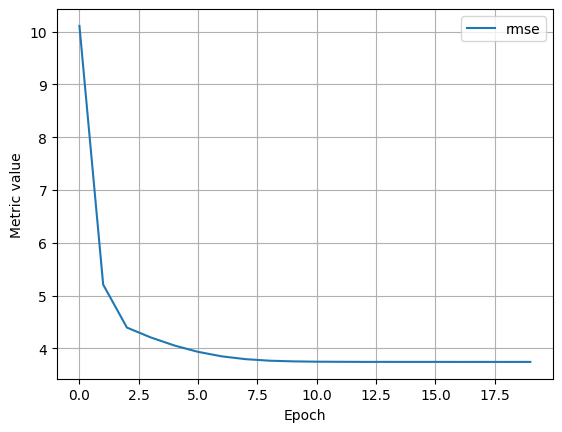

In [ ]:
# Experiment 1 - Training with one input feature: TRIP_MILES

# Define the hyperparameters.
settings_1 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_1 = create_model(settings_1, metrics)

experiment_1 = train_model('one_feature', model_1, training_df, 'FARE', settings_1)

ml_edu.results.plot_experiment_metrics(experiment_1, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_1, training_df, 'FARE')



1.   The model converges around 5 epochs.
2.   The model appears to fit the sample dataset well.



Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 48.3916 - rmse: 6.9564
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.6909 - rmse: 6.9059
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.2250 - rmse: 6.8720
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.7595 - rmse: 6.9108
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.6033 - rmse: 6.8995
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 48.1127 - rmse: 6.9363
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 48.8328 - rmse: 6.9880
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.6044 - rmse: 6.8996
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.8779 - rmse: 6.9194
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 48.3292 - rmse: 6.9519
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 47.1170 - rmse: 6.8642
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 48.5443 - rmse: 6.9674
E

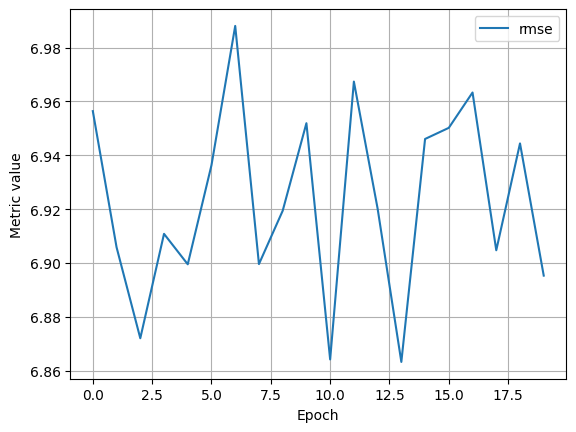

In [ ]:
# Experiment 2 - Increasing the learning rate to 1.0

# Define the hyperparameters.
settings_2 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 1.0,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_2 = create_model(settings_2, metrics)

experiment_2 = train_model('one_feature', model_2, training_df, 'FARE', settings_2)

ml_edu.results.plot_experiment_metrics(experiment_2, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_2, training_df, 'FARE')



1.   The model generally doesn't converge with a learning rate = 1.0. The learning rate appears to be too high for this model because the loss curve bounces around substantially with each iteration. Additionally, the predicted model doesn't appear to be an ideal fit for the actual values.



Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1277.8427 - rmse: 35.7469
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1226.4346 - rmse: 35.0205
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1176.0977 - rmse: 34.2943
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1126.3606 - rmse: 33.5613
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1078.1238 - rmse: 32.8348
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1031.0137 - rmse: 32.1094
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 985.0401 - rmse: 31.3853 
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 939.8685 - rmse: 30.6573
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 895.8246 - rmse: 29.9303
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 853.0648 - rmse: 29.2073
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 811.1539 - rmse: 28.4808
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - l

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


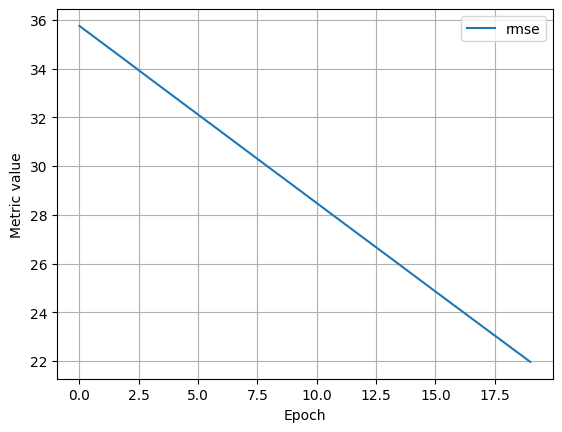

In [ ]:
# Experiment 3 - Decreasing the learning rate to 0.0001

# Define the hyperparameters.
settings_3 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.0001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_3 = create_model(settings_3, metrics)

experiment_3 = train_model('one_feature', model_3, training_df, 'FARE', settings_3)

ml_edu.results.plot_experiment_metrics(experiment_3, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_3, training_df, 'FARE')



1.   A learning rate = 0.0001 is too low (and slow) for this model. However, that is not to say a learning rate of 0.0001 will never converge; increasing the epochs may result in convergence but will significantly consume time.



Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 361.7206 - rmse: 19.0190
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 334.2291 - rmse: 18.2819
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 308.2621 - rmse: 17.5574
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 283.2408 - rmse: 16.8298
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 259.5927 - rmse: 16.1119
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 236.8909 - rmse: 15.3913
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 215.3870 - rmse: 14.6761
Epoch 8/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 194.9766 - rmse: 13.9634
Epoch 9/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 175.8048 - rmse: 13.2591
Epoch 10/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 157.6642 - rmse: 12.5564
Epoch 11/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 140.5827 - rmse: 11.8568
Epoch 12/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 124.7380 - rmse: 11.1686
E

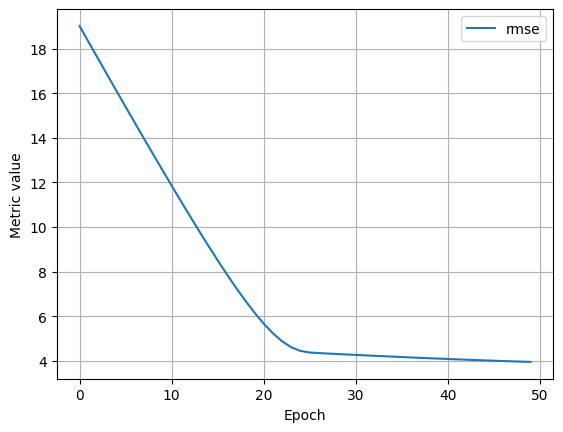

In [ ]:
# Experiment 4 - Increasing the batch size to 500 with a learning rate of 0.001

# Define the hyperparameters.
settings_4 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 50,
    batch_size = 500,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_4 = create_model(settings_4, metrics)

experiment_4 = train_model('one_feature', model_4, training_df, 'FARE', settings_4)

ml_edu.results.plot_experiment_metrics(experiment_4, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_4, training_df, 'FARE')



1.   Increasing the batch size increased the processing time per epoch, but didn't necessarily converge with a learning rate at 0.001 with just 20 epochs. Increasing the number of epochs has a positive effect on convergence.




In [ ]:
#@title Takeways from Experiments

# A learning rate that is too high for a model generally doesn't converge.
# The loss curve bounces around inconsistently with each iteration.

# A learning rate that is too low for a model can converge by increasing the
# number of epochs, but will consume a lot of time that it's not worth it.

# A learning rate that is an ideal fit for a model can converge sooner with a
# simultaneously increased batch size and epochs.

# TRIP_MILES demonstrates strong predictive power as a single feature.

### How can multiple features contribute to a better model?
# Previously, I discovered TRIP_MILES and TRIP_SECONDS had the strongest correlation
# to a higher FARE. I'll use those two features to test for a better model.

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 633819.9375 - rmse: 796.1281  
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5515.7246 - rmse: 74.2679  
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 91.3170 - rmse: 9.5560
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 59.1188 - rmse: 7.6889
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 36.7593 - rmse: 6.0629
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 23.2794 - rmse: 4.8249
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 17.1201 - rmse: 4.1376
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.8762 - rmse: 3.8570
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.1452 - rmse: 3.7610
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 13.7023 - rmse: 3.7017
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13.5401 - rmse: 3.6797
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13.3412 - r

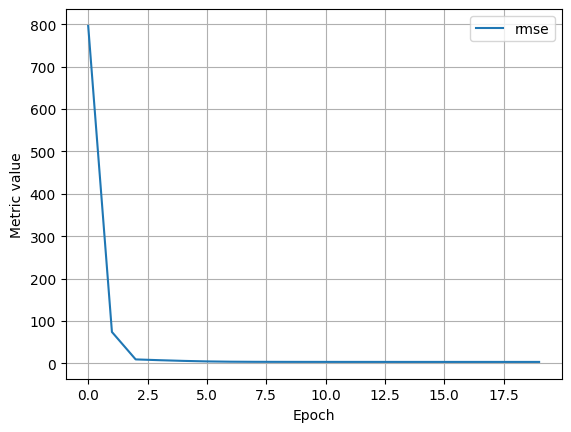

In [ ]:
#@title Model Using Multiple Features

# Define the hyperparameters.
settings_5 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES', 'TRIP_SECONDS']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_5 = create_model(settings_5, metrics)

experiment_5 = train_model('two_features', model_5, training_df, 'FARE', settings_5)

ml_edu.results.plot_experiment_metrics(experiment_5, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_5, training_df, 'FARE')



1.   The two-feature model produces better results. Previously with one feature, TRIP_MILES, the model converged around 5 epochs under the same conditions and resulted in a loss of 14.0321 after 20 epochs. The two-feature model converged around 2.5 epochs and resulted in a loss of 13.0330 after 20 epochs.
2.   Additionally, RMSE using one feature was 3.7459 and with two features is 3.6101. Meaning, using two features makes predictions that are on average 0.13 closer to the actual FARE values.





Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 324.1856 - rmse: 18.0052
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 93.8307 - rmse: 9.6866  
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 61.4066 - rmse: 7.8362
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 37.6482 - rmse: 6.1358
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 22.6814 - rmse: 4.7625
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 15.4635 - rmse: 3.9324
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 13.1629 - rmse: 3.6281
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.5134 - rmse: 3.5374
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 12.2925 - rmse: 3.5061
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 12.1895 - rmse: 3.4913
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1350 - rmse: 3.4835
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1128 - rmse: 3.48

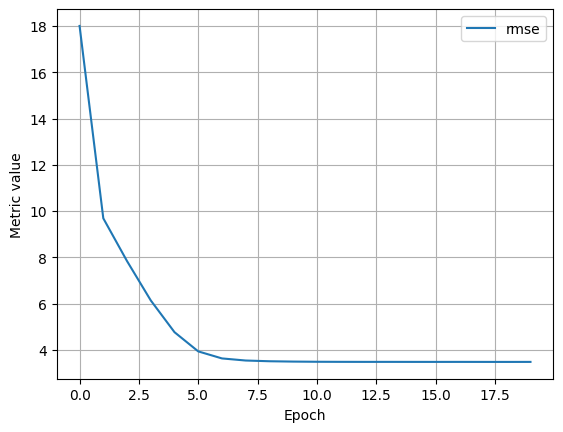

In [ ]:
# How does changing TRIP_SECONDS to TRIP_MINUTES affect the model?
# Reason for exploration: Because TRIP_SECONDS values are 60x larger than TRIP_MINUTES.

# Experiment 2 Using Multiple Features

# Define the hyperparameters.
training_df['TRIP_MINUTES'] = training_df['TRIP_SECONDS'] / 60

settings_6 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES', 'TRIP_MINUTES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_6 = create_model(settings_6, metrics)

experiment_6 = train_model('two_features', model_6, training_df, 'FARE', settings_6)

ml_edu.results.plot_experiment_metrics(experiment_6, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_6, training_df, 'FARE')



1.   Converting TRIP_SECONDS to TRIP_MINUTES resulted in an even better model. Does larger feature values have potential to skew the loss curve or the model in general?
2.   TRIP_MINUTES improved the model's predictions by resulting in a loss of 12.0966, but appears to have converged after 5 epochs rather than ~2.5 epochs using TRIP_SECONDS.
3.   Additionally, RMSE has improved. RMSE using TRIP_SECONDS was 3.6101; using TRIP_MINUTES is 3.4780, which is on average 0.14 closer to the actual FARE. Previously, RMSE using two features was 0.13 closer to the actual FARE.





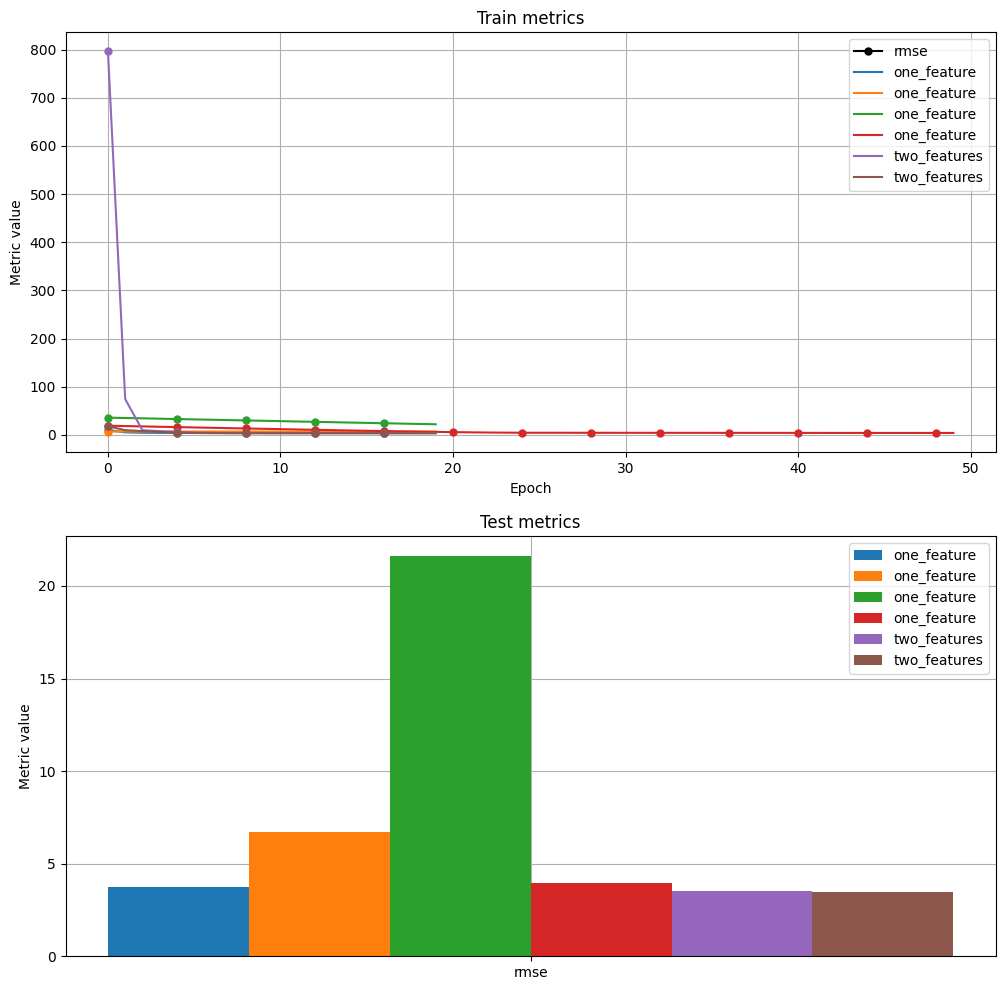

In [ ]:
ml_edu.results.compare_experiment(
    [experiment_1, experiment_2, experiment_3, experiment_4, experiment_5, experiment_6],
    ['rmse'],
    training_df,
    training_df['FARE'].values)

In [ ]:
#@title Model Validation - Making Predictions
def format_currency(x):
  return "${:.2f}".format(x)

def build_batch(df, batch_size):
  batch = df.sample(n=batch_size).copy()
  batch.set_index(np.arange(batch_size), inplace=True)
  return batch

def predict_fare(model, df, features, label, batch_size=50):
  batch = build_batch(df, batch_size)
  predicted_values = model.predict_on_batch(x={name: batch[name].values for name in features})

  data = {"PREDICTED_FARE": [], "OBSERVED_FARE": [], "L1_LOSS": [],
          features[0]: [], features[1]: []}
  for i in range(batch_size):
    predicted = predicted_values[i][0]
    observed = batch.at[i, label]
    data["PREDICTED_FARE"].append(format_currency(predicted))
    data["OBSERVED_FARE"].append(format_currency(observed))
    data["L1_LOSS"].append(format_currency(abs(observed - predicted)))
    data[features[0]].append(batch.at[i, features[0]])
    data[features[1]].append("{:.2f}".format(batch.at[i, features[1]]))

  output_df = pd.DataFrame(data)
  return output_df

def show_predictions(output):
  header = "-" * 80
  banner = header + "\n" + "|" + "PREDICTIONS".center(78) + "|" + "\n" + header
  print(banner)
  print(output)
  return

In [ ]:
# Making predictions
output = predict_fare(experiment_6.model, training_df, experiment_6.settings.input_features, 'FARE')
show_predictions(output)

--------------------------------------------------------------------------------
|                                 PREDICTIONS                                  |
--------------------------------------------------------------------------------
   PREDICTED_FARE OBSERVED_FARE L1_LOSS  TRIP_MILES TRIP_MINUTES
0          $46.10        $46.25   $0.15       16.04        64.18
1          $12.64        $12.95   $0.31        3.40        12.65
2          $20.86        $20.25   $0.61        6.89        20.08
3          $33.19        $33.25   $0.06       12.38        27.92
4          $45.50        $42.00   $3.50       16.20        58.00
5          $14.32        $13.00   $1.32        4.20        13.00
6           $5.85         $5.50   $0.35        0.70         4.00
7          $45.12        $44.25   $0.87       17.29        40.82
8           $7.12         $6.50   $0.62        1.10         7.00
9          $32.90        $33.25   $0.35       12.90        19.00
10         $45.96        $45.50   $0.46   



1.   The predicted values are (on average) consistently close to the label value, minus a few exceptions. The model appears to do very well predicting the actual FARE value.

